# Generation of prompts for generating Dataset

## 0. Simulated inflation: base level + decaying shocks

Inflation is modelled as a constant base level plus a few large shocks. Each shock builds up over `rise` months and then decays with a half-life of `half_life` months; there is no small month-to-month noise, so the series is flat between shocks.

- **Random shocks**: arrive about once every 15 years (`shock_rate`), mostly upward (`shock_up`), sometimes downward (`p_down`, `shock_down`).
- **Fixed shocks**: pass `shocks=[("1974-01", 10), ...]` to place them by hand, e.g. to mimic the real history or to have known break dates as ground truth.

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def shock_shape(n_months, rise=4, half_life=12):
    """Response to one shock of size 1: builds up over ~`rise` months, then decays.

    Difference of two exponentials, scaled so that the peak is 1. rise=0 gives an instant jump followed by pure decay.
    """
    t = np.arange(n_months)
    slow = 0.5 ** (t / half_life)
    if rise <= 0:
        return slow
    shape = slow - np.exp(-t / rise)
    return shape / shape.max()


def simulate_inflation(start="1947-01-01", n_months=960, base=2.5, shocks=None, seed=7,
                       shock_rate=1 / 180, shock_up=(9.0, 3.0), p_down=0.3, shock_down=(-5.0, 1.5),
                       rise=4, half_life=12):
    """Monthly inflation (% p.a.): base level + shocks that build up and decay.

    shocks: list of (date, size) to place the shocks by hand; if None they are drawn at random.
    Returns (inflation series, list of (shock month, size)).
    """
    idx = pd.date_range(start, periods=n_months, freq="MS")
    resp = shock_shape(n_months, rise, half_life)
    pi = np.full(n_months, base, dtype=float)

    if shocks is None:
        rng = np.random.default_rng(seed)
        months = np.flatnonzero(rng.random(n_months) < shock_rate)
        shocks = [(idx[t], rng.normal(*shock_down) if rng.random() < p_down else rng.normal(*shock_up)) for t in months]

    placed = []
    for date, size in shocks:
        t = idx.get_indexer([pd.Timestamp(date).to_period("M").to_timestamp()])[0]
        if t < 0:
            continue  # shock outside the simulated period
        pi[t:] += size * resp[: n_months - t]
        placed.append((idx[t].strftime("%Y-%m"), round(float(size), 1)))
    return pd.Series(pi, idx, name="inflation"), placed

seed 7: mean 2.49  min -3.3  max 11.6  shocks [('1947-07', 7.1), ('1950-02', -5.0), ('1956-07', -5.7), ('1998-03', 9.1), ('2019-02', -5.6)]
seed 11: mean 3.18  min 2.5  max 15.8  shocks [('1974-06', 11.1), ('1987-09', 13.3)]
seed 23: mean 2.96  min 2.5  max 13.5  shocks [('2010-08', 5.5), ('2019-06', 10.9)]


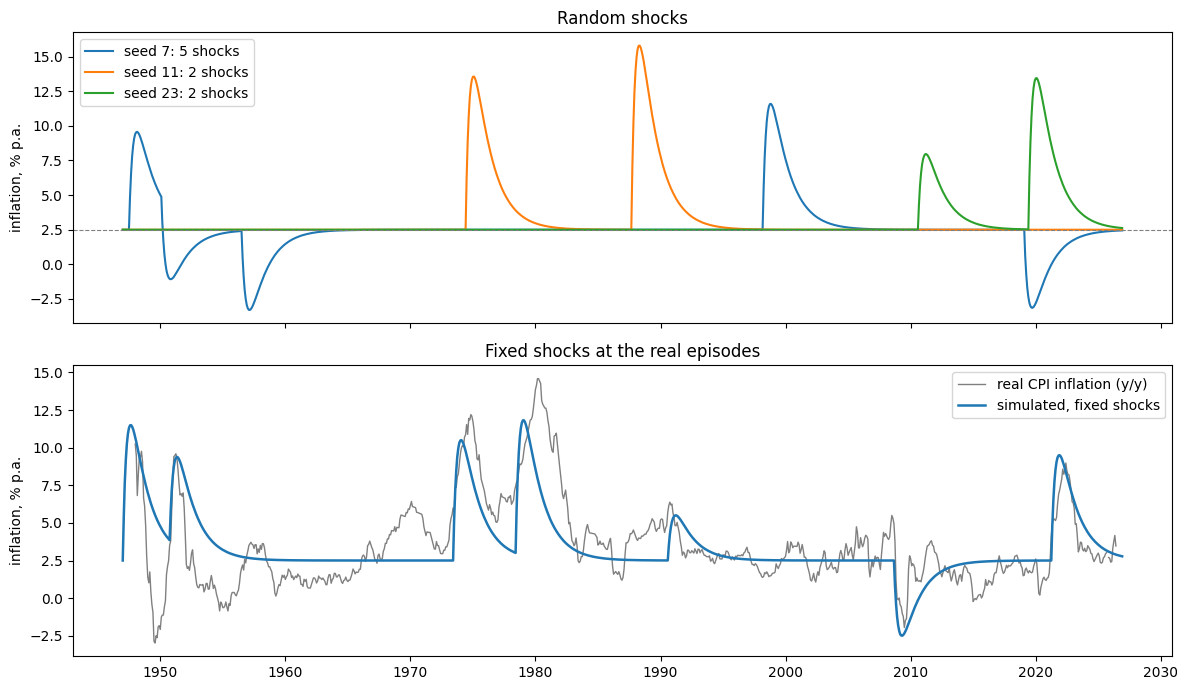

In [7]:
# Random shocks for a few seeds
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for seed in (7, 11, 23):
    sim, placed = simulate_inflation(seed=seed)
    axes[0].plot(sim.index, sim.values, lw=1.5, label=f"seed {seed}: {len(placed)} shocks")
    print(f"seed {seed}: mean {sim.mean():.2f}  min {sim.min():.1f}  max {sim.max():.1f}  shocks {placed}")
axes[0].axhline(2.5, color="grey", lw=0.8, ls="--")
axes[0].set_ylabel("inflation, % p.a.")
axes[0].set_title("Random shocks")
axes[0].legend()

# Fixed shocks roughly at the real US episodes, compared with real CPI inflation
history = [("1947-01", 9), ("1950-10", 6), ("1973-06", 8), ("1978-06", 9), ("1990-08", 3),
           ("2008-09", -5), ("2021-04", 7)]
sim_hist, _ = simulate_inflation(shocks=history, n_months=12 * 80)
cpi = pd.read_csv("../../data/TSs_macro/CPIAUCSL.csv", parse_dates=["Date"]).set_index("Date")["value"]
cpi_yoy = cpi.pct_change(12, fill_method=None) * 100
axes[1].plot(cpi_yoy.index, cpi_yoy.values, color="grey", lw=1, label="real CPI inflation (y/y)")
axes[1].plot(sim_hist.index, sim_hist.values, lw=1.8, label="simulated, fixed shocks")
axes[1].set_ylabel("inflation, % p.a.")
axes[1].set_title("Fixed shocks at the real episodes")
axes[1].legend()
plt.tight_layout()
plt.show()

## 0b. Simulated unemployment: base level + recessions

Same building block as the inflation (`shock_shape` from section 0), different speed: in a recession unemployment rises within months and then falls back over years. The defaults therefore use a longer rise (`rise=8`) and a much longer half-life (`half_life=30`) than for inflation, and shocks only go upward.

- **Random recessions**: about one every 8 years (`shock_rate`), size `shock_size` percentage points.
- **Fixed recessions**: pass `shocks=[(date, size)]` or `(date, size, rise, half_life)` to give each recession its own speed, e.g. 2020 with an almost instant jump and a fast recovery.

In [15]:
def simulate_unemployment(start="1948-01-01", n_months=12 * 79, base=4.5, shocks=None, seed=7,
                          shock_rate=1 / 96, shock_size=(3.5, 1.5), rise=8, half_life=30):
    """Monthly unemployment rate (%): base level + recessions that push it up and then fade.

    Same building block as the inflation simulation (shock_shape), but unemployment rises within months
    and falls back over years, so the defaults use a longer rise and a much longer half-life.
    shocks: list of (date, size) or (date, size, rise, half_life) to place recessions by hand, each with its own
    speed (e.g. 2020: almost instant jump, fast recovery); if None they are drawn at random (always upward).
    Returns (unemployment series, list of placed shocks).
    """
    idx = pd.date_range(start, periods=n_months, freq="MS")
    u = np.full(n_months, base, dtype=float)

    if shocks is None:
        rng = np.random.default_rng(seed)
        months = np.flatnonzero(rng.random(n_months) < shock_rate)
        shocks = [(idx[t], max(0.5, rng.normal(*shock_size))) for t in months]

    placed = []
    for shock in shocks:
        date, size = shock[0], shock[1]
        r, hl = (shock[2], shock[3]) if len(shock) == 4 else (rise, half_life)
        t = idx.get_indexer([pd.Timestamp(date).to_period("M").to_timestamp()])[0]
        if t < 0:
            continue  # shock outside the simulated period
        u[t:] += size * shock_shape(n_months - t, r, hl)
        placed.append((idx[t].strftime("%Y-%m"), round(float(size), 1)))
    return pd.Series(u, idx, name="unemployment"), placed

seed 7: mean 5.93  max 10.6  recessions [('1948-07', 1.4), ('1951-02', 5.3), ('1957-07', 2.5), ('1999-03', 1.8), ('2004-09', 5.4), ('2020-02', 3.4), ('2021-02', 1.5), ('2024-12', 3.0)]
seed 11: mean 5.72  max 11.4  recessions [('1975-06', 2.2), ('1988-09', 3.2), ('1997-02', 2.6), ('2001-10', 2.3), ('2017-08', 4.8), ('2021-10', 5.0)]
seed 23: mean 5.76  max 12.7  recessions [('1977-07', 6.0), ('1979-08', 0.9), ('2011-08', 3.8), ('2013-06', 4.0), ('2020-06', 2.3), ('2022-10', 3.5), ('2026-08', 5.3)]


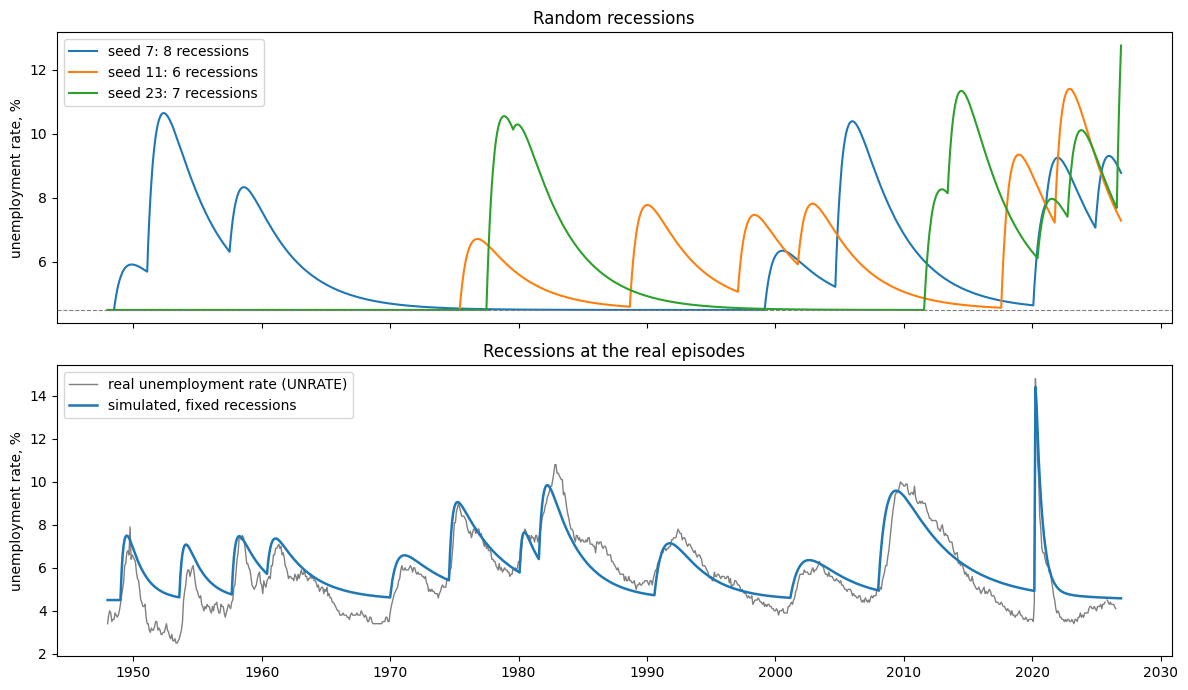

In [9]:
# Random recessions for a few seeds
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for seed in (7, 11, 23):
    sim_u, placed = simulate_unemployment(seed=seed)
    axes[0].plot(sim_u.index, sim_u.values, lw=1.5, label=f"seed {seed}: {len(placed)} recessions")
    print(f"seed {seed}: mean {sim_u.mean():.2f}  max {sim_u.max():.1f}  recessions {placed}")
axes[0].axhline(4.5, color="grey", lw=0.8, ls="--")
axes[0].set_ylabel("unemployment rate, %")
axes[0].set_title("Random recessions")
axes[0].legend()

# Recessions placed at the real US episodes: (start, size, rise, half-life in months)
recessions = [("1949-01", 3.0, 3, 10), ("1953-08", 2.5, 3, 12), ("1957-09", 2.8, 3, 18), ("1960-06", 2.0, 4, 24),
              ("1970-01", 2.0, 6, 30), ("1974-08", 3.8, 3, 30), ("1980-02", 2.0, 2, 12), ("1981-08", 4.0, 4, 20),
              ("1990-08", 2.5, 8, 22), ("2001-03", 1.8, 10, 26), ("2008-01", 4.8, 8, 34), ("2020-03", 9.5, 0.4, 4)]
sim_u_hist, _ = simulate_unemployment(shocks=recessions)
unrate = pd.read_csv("../../data/TSs_macro/UNRATE.csv", parse_dates=["Date"]).set_index("Date")["value"]
axes[1].plot(unrate.index, unrate.values, color="grey", lw=1, label="real unemployment rate (UNRATE)")
axes[1].plot(sim_u_hist.index, sim_u_hist.values, lw=1.8, label="simulated, fixed recessions")
axes[1].set_ylabel("unemployment rate, %")
axes[1].set_title("Recessions at the real episodes")
axes[1].legend()
plt.tight_layout()
plt.show()

## 0c. Calibration to the real series and saving

Same procedure as for the crude oil / natural gas series in `data_gen.ipynb`: estimate the parameters of the shock models from the real series (CPI inflation, unemployment rate), simulate 1970-2025 and save the result in the same files and format (`full_series/full_sampled_*.csv`, `sampled_*.csv` with `Date,Kurs` and `TSs/*.csv` with `Date,Stock_Price`). Requires sections 0 and 0b to be run first.


In [ ]:
"""
Calibration of the shock models of sections 0 and 0b to the real US series, then one simulated path per series.

Same steps as for the crude oil and natural gas series (data_gen.ipynb, sections 2.6 / 2.7):
  1. load the real series (inflation = y/y change of CPIAUCSL, unemployment = UNRATE),
  2. separate the shocks from the base level and estimate the parameters of the simulator,
  3. simulate one path 1970-2025 with the fitted parameters,
  4. save it as Date,Kurs in data/stock_prices/full_series/ (+ the same file in data/stock_prices/ and data/TSs/),
  5. plot real vs simulated.

Estimation (the counterpart of the 3-sigma jump detector of the commodity models):
  base       : median of the real series (inflation: shocks go both ways) or its 20 % quantile (unemployment: shocks only go up,
               so the lower part of the series is the base level).
  shocks     : months where |series - base| is more than K_SIGMA robust standard deviations (MAD) away from the base; active
               months that are at most GAP months apart belong to one episode.
  shock_rate : episodes per month; size = excess at the episode's peak (up and down; p_down = share of downward episodes).
  rise       : the build-up time of the shock shape is chosen so that its peak comes as many months after the shock starts as in the
               real episodes (start = last month before the peak with less than 20 % of the peak; median over the episodes).
  half_life  : decay after the peak, fitted on log(excess / peak) until the excess is below 20 % of the peak (median over episodes).
"""

import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path("../../data")
OUT_FULL = DATA / "stock_prices" / "full_series"   # full_sampled_<name>.csv   (Date, Kurs)
OUT_SAMPLED = DATA / "stock_prices"                # sampled_<name>.csv        (Date, Kurs)
OUT_TS = DATA / "TSs"                              # <name>.csv                (Date, Stock_Price)
SIM_START, SIM_MONTHS, SIM_SEED = "1970-01-01", 12 * 56, 3   # 1970-01 .. 2025-12, like the commodity paths
K_SIGMA, GAP = 2.0, 6


def rise_for_peak_time(t_peak, half_life):
    """The rise of shock_shape whose peak lies t_peak months after the start (given the half-life)."""
    grid = np.linspace(0.3, 36, 300)
    times = np.array([int(np.argmax(shock_shape(240, r, half_life))) for r in grid])
    return float(grid[int(np.argmin(np.abs(times - t_peak)))])


def calibrate_shocks(real, base_quantile, k=K_SIGMA, gap=GAP):
    """Base level, shock rate / sizes / speed of a monthly series that is a base level plus decaying shocks."""
    real = real.dropna()
    base = float(real.quantile(base_quantile))
    excess = real - base
    sigma = 1.4826 * float((excess - excess.median()).abs().median())   # robust noise scale
    active = np.flatnonzero((excess.abs() > k * sigma).to_numpy())

    runs, start, prev = [], None, None            # episodes: runs of active months, merged over gaps of <= `gap` months
    for i in active:
        if start is None:
            start = prev = i
        elif i - prev <= gap:
            prev = i
        else:
            runs.append((start, prev)); start = prev = i
    if start is not None:
        runs.append((start, prev))

    rows = []
    for s, e in runs:
        seg = excess.iloc[s:e + 1].to_numpy()
        p = int(np.argmax(np.abs(seg)))
        peak = float(seg[p])
        pre = excess.iloc[:s + p + 1].to_numpy() / peak       # build-up: months from the last point below 20 % of the peak
        low = np.flatnonzero(pre < 0.2)
        t_up = max((s + p) - (int(low[-1]) if low.size else 0), 1)
        post = excess.iloc[s + p:].to_numpy() / peak          # decay after the peak, relative to the peak
        below = np.flatnonzero(post < 0.2)
        n_dec = int(below[0]) if below.size else len(post)
        half_life = np.nan
        if n_dec >= 4:
            slope = np.polyfit(np.arange(n_dec), np.log(np.clip(post[:n_dec], 1e-3, None)), 1)[0]
            if slope < 0:
                half_life = float(np.log(2) / -slope)
        rows.append({"start": excess.index[s], "peak_month": excess.index[s + p], "size": peak,
                     "months_to_peak": t_up, "half_life": half_life})
    ep = pd.DataFrame(rows)
    up, down = ep[ep["size"] > 0]["size"], ep[ep["size"] < 0]["size"]
    half_life = float(ep["half_life"].median())
    rise = rise_for_peak_time(float(ep["months_to_peak"].median()), half_life)
    return {"base": base, "sigma": sigma, "shock_rate": len(ep) / len(real), "n_episodes": len(ep),
            "up": (float(up.mean()), float(up.std(ddof=1)) if len(up) > 1 else 1.0),
            "down": (float(down.mean()), float(down.std(ddof=1)) if len(down) > 1 else 1.0) if len(down) else None,
            "p_down": len(down) / max(len(ep), 1), "rise": rise, "half_life": half_life,
            "months_to_peak": float(ep["months_to_peak"].median()), "episodes": ep, "excess": excess}


# ── 1. real series ───────────────────────────────────────────────
cpi = pd.read_csv(DATA / "TSs_macro" / "CPIAUCSL.csv", parse_dates=["Date"]).set_index("Date")["value"].sort_index()
real_inflation = (cpi.pct_change(12, fill_method=None) * 100).dropna()
real_unemployment = pd.read_csv(DATA / "TSs_macro" / "UNRATE.csv", parse_dates=["Date"]).set_index("Date")["value"].sort_index().dropna()
print(f"real inflation:    {len(real_inflation)} months, {real_inflation.index.min():%Y-%m} to {real_inflation.index.max():%Y-%m}")
print(f"real unemployment: {len(real_unemployment)} months, {real_unemployment.index.min():%Y-%m} to {real_unemployment.index.max():%Y-%m}\n")

# ── 2. estimate ──────────────────────────────────────────────────
cal_inf = calibrate_shocks(real_inflation, base_quantile=0.5)
cal_une = calibrate_shocks(real_unemployment, base_quantile=0.2)
for name, cal in (("inflation", cal_inf), ("unemployment", cal_une)):
    print(f"── Calibrated parameters: {name} ─────────────────────")
    print(f"  base       = {cal['base']:.2f}")
    print(f"  sigma      = {cal['sigma']:.2f}   (robust noise scale, MAD)")
    print(f"  episodes   = {cal['n_episodes']}   -> shock_rate = 1/{1 / cal['shock_rate']:.0f} months")
    print(f"  up shocks  = N({cal['up'][0]:.2f}, {cal['up'][1]:.2f}),  p_down = {cal['p_down']:.2f}, down shocks = {cal['down']}")
    print(f"  peak after = {cal['months_to_peak']:.0f} months (median) -> rise = {cal['rise']:.1f},  half_life = {cal['half_life']:.1f} months\n")

# ── 3. simulate one path 1970-2025 ───────────────────────────────
sim_inflation, shocks_i = simulate_inflation(
    start=SIM_START, n_months=SIM_MONTHS, seed=SIM_SEED, base=cal_inf["base"], shock_rate=cal_inf["shock_rate"],
    shock_up=cal_inf["up"], p_down=cal_inf["p_down"], shock_down=cal_inf["down"] or (-5.0, 1.5),
    rise=cal_inf["rise"], half_life=cal_inf["half_life"])
sim_unemployment, shocks_u = simulate_unemployment(
    start=SIM_START, n_months=SIM_MONTHS, seed=SIM_SEED, base=cal_une["base"], shock_rate=cal_une["shock_rate"],
    shock_size=cal_une["up"], rise=cal_une["rise"], half_life=cal_une["half_life"])
print(f"simulated inflation:    {len(shocks_i)} shocks, mean {sim_inflation.mean():.2f}, range {sim_inflation.min():.1f} to {sim_inflation.max():.1f}")
print(f"simulated unemployment: {len(shocks_u)} recessions, mean {sim_unemployment.mean():.2f}, range {sim_unemployment.min():.1f} to {sim_unemployment.max():.1f}\n")

# ── 4. save: Date,Kurs (full_series/, stock_prices/) and Date,Stock_Price (TSs/) ──
for name, sim in (("inflation", sim_inflation), ("unemployment", sim_unemployment)):
    out = pd.DataFrame({"Date": sim.index.strftime("%Y-%m-%d"), "Kurs": sim.round(4).values})
    for folder, fname, col in ((OUT_FULL, f"full_sampled_{name}.csv", "Kurs"), (OUT_SAMPLED, f"sampled_{name}.csv", "Kurs"),
                               (OUT_TS, f"{name}.csv", "Stock_Price")):
        os.makedirs(folder, exist_ok=True)
        out.rename(columns={"Kurs": col}).to_csv(folder / fname, index=False)
        print(f"Saved {folder / fname}  ({len(out)} rows)")

# ── 5. plot real vs simulated, and the detected episodes ─────────────
fig, axes = plt.subplots(2, 2, figsize=(16, 8), sharex="col")
for col, (name, real, sim, cal, unit) in enumerate((
        ("Inflation", real_inflation, sim_inflation, cal_inf, "% p.a."),
        ("Unemployment", real_unemployment, sim_unemployment, cal_une, "%"))):
    ax = axes[0, col]
    ax.plot(real.index, real.values, color="grey", lw=1.2, label="real")
    ax.plot(sim.index, sim.values, color="#2a78d6", lw=1.6, label="simulation (1970-2025, calibrated)")
    ax.axhline(cal["base"], color="k", lw=0.8, ls="--", label=f"base = {cal['base']:.2f}")
    ax.set_ylabel(unit); ax.set_title(f"{name}: simulation vs real"); ax.legend()
    ax = axes[1, col]
    ax.plot(cal["excess"].index, cal["excess"].values, color="grey", lw=1)
    ax.axhline(0, color="k", lw=0.8)
    for sgn in (1, -1):
        ax.axhline(sgn * K_SIGMA * cal["sigma"], color="#eda100", lw=0.8, ls=":")
    ep = cal["episodes"]
    ax.scatter(ep["peak_month"], ep["size"], color="#eb6834", s=22, zorder=3, label=f"{len(ep)} detected episodes (peaks)")
    ax.set_ylabel(f"{unit} above base"); ax.set_title(f"{name}: real series minus base, detected shocks"); ax.legend()
plt.tight_layout()
plt.show()


## 1. imports 

In [10]:
import pandas as pd

## 2. Load sample data

## 3. Article creation

### 3.1 articles_all_commodities_baseline_seed7


In [12]:
"""
Prompt template for generating synthetic financial news articles
about INFLATION and UNEMPLOYMENT, conditioned on:
  - The article date
  - 21 days of history ending on that date, for EACH sampled series
    (both are percent rates)
  - The set of 1-4 commodities the article discusses
  - The current price level of each commodity

(No break-referencing in this version -- break_in_window is always False,
break_date/break_magnitudes are always empty. The break-block parameters
are kept in the signature so build_prompt still works unchanged if break
support is reintroduced later.)
s
IMPORTANT: The generated articles NEVER name the commodities directly (no
"inflation", "unemployment", "CPI", "jobless", etc.) and NEVER
state exact prices or percentage figures. Instead:
  - Each commodity is referred to via vague phrases ("the price gauge", "the labor-market gauge",
    "the commodity") or descriptive references to its use case.
  - Prices only shape the narrative's TONE (bullish/bearish/calm/volatile).

HARDENING:
  - DECOY MENTIONS: with probability `p_decoy`, the article may explicitly
    name 1-2 OTHER commodities (not in the sampled set) in passing.
  - AMBIGUOUS THEMES: with probability `p_ambiguous_theme`, one theme is
    drawn from a shared pool fitting several commodities.
  - VARIABLE SIGNAL COUNT: number of themes per commodity is sampled.
  - STYLE DISTORTIONS: with probability `p_style_distortion`, the model is
    instructed to reproduce some of the surface-level noise patterns found
    in the real Reuters-21578 corpus (terse stub format, hedging language,
    fraction-style numbers, wire boilerplate, etc.) so that generated
    articles are stylistically harder to classify, matching the real data.

Usage:
    from prompt_template import build_prompt
    prompt = build_prompt(date, commodities, prices_by_commodity,
                          break_in_window, break_date, break_magnitudes, seed)
"""

import numpy as np

# ── Reuters-21578 word count distribution ─────────────────────────
_REUTERS_MEAN = 135.8
_REUTERS_VAR  = 18332.6
_REUTERS_MIN  = 2
_REUTERS_MAX  = 1669
_LN_SIGMA = np.sqrt(np.log(1 + _REUTERS_VAR / _REUTERS_MEAN**2))
_LN_MU    = np.log(_REUTERS_MEAN) - 0.5 * _LN_SIGMA**2


def sample_n_words(rng: np.random.Generator,
                   word_counts: list[int] | np.ndarray | None = None) -> int:
    """Sample article length: a uniform random integer between 50 and 150 words."""
    return int(rng.integers(50, 151))


# ── Commodity-specific metadata ───────────────────────────────────
COMMODITY_META = {
    "inflation": {
        "unit":      "% y/y",
        "price_col": "price_inflation",
        "family":    "macro",
        "signals": [
            ("energy and fuel costs feeding through to shop prices",            1950, 9999),
            ("wage-price spiral concerns as unions press for pay increases",        1950, 9999),
            ("a central bank weighing a rate decision against rising price pressures", 1950, 9999),
            ("expectations among households and firms about future price growth",   1960, 9999),
            ("food and grocery prices climbing faster than household budgets",      1900, 9999),
            ("rent and housing costs lifting the shelter component of broad price measures", 1960, 9999),
            ("supply chain bottlenecks pushing up the cost of goods",               1990, 9999),
            ("government price and wage controls meant to hold down price growth",  1971, 1980),
            ("the aftermath of the oil embargo shock still working through prices", 1973, 1982),
            ("tight monetary policy aimed at bringing price growth back to target", 1979, 9999),
            ("a weaker currency raising the cost of imported goods",                1950, 9999),
            ("fiscal stimulus and strong demand outrunning supply",                 2008, 9999),
            ("a pandemic-era rebound in demand meeting constrained supply",         2020, 9999),
            ("a sharp drop in fuel costs pulling headline price growth lower",      1950, 9999),
            ("core price measures stripping out food and energy staying sticky",    1980, 9999),
            ("bond markets pricing in higher long-term price growth",               1980, 9999),
            ("policymakers debating whether price pressures are transitory or persistent", 1970, 9999),
            ("a monthly price report coming in hotter than analysts had expected",  1950, 9999),
            ("a monthly price report coming in softer than analysts had expected",  1950, 9999),
            ("a risk of outright falling prices after a deep downturn",             1990, 9999),
        ],
        "forbidden": [
            '"inflation"', '"inflationary"', '"disinflation"', '"deflation"',
            '"CPI"', '"consumer price index"', '"consumer prices"', '"PCE"',
            '"price index"', '"cost of living"',
        ],
        "indirect": [
            ('"the pace at which everyday prices are rising"',            1900, 9999),
            ('"the erosion of purchasing power"',                         1900, 9999),
            ('"the figure households feel at the checkout"',              1900, 9999),
            ('"the broad measure of how fast the cost of a typical shopping basket moves"', 1950, 9999),
            ('"the yardstick central bankers watch to set policy"',       1950, 9999),
            ('"the gauge of price pressures across the economy"',         1950, 9999),
            ('"the headline price-growth reading"',                       1950, 9999),
            ('"the indicator the central bank is mandated to keep stable"', 1950, 9999),
            ('"the macro indicator in question"',                         1900, 9999),
            ('"the economic gauge in the spotlight"',                     1900, 9999),
        ],
    },
    "unemployment": {
        "unit":      "% of labor force",
        "price_col": "price_unemployment",
        "family":    "macro",
        "signals": [
            ("layoff announcements from large manufacturers",                      1900, 9999),
            ("a rising number of people filing new claims for state benefits",     1950, 9999),
            ("employers pulling back on hiring amid weak order books",             1900, 9999),
            ("a monthly employment report showing weaker-than-expected job creation", 1950, 9999),
            ("a monthly employment report showing stronger-than-expected job creation", 1950, 9999),
            ("plant closures hitting industrial regions hard",                     1900, 9999),
            ("youth and long-term out-of-work numbers drawing political attention", 1960, 9999),
            ("a tight labor market with employers struggling to fill vacancies",   1950, 9999),
            ("workers dropping out of the labor force and discouraged job seekers", 1950, 9999),
            ("government job-creation and retraining programs",                    1930, 9999),
            ("a recession deepening and spreading to services",                    1900, 9999),
            ("a recovery in hiring following a downturn",                          1900, 9999),
            ("automation and offshoring displacing factory workers",               1970, 9999),
            ("wage growth cooling as slack in the labor market builds",            1950, 9999),
            ("extended benefit programs for people out of work",                   1950, 9999),
            ("a sharp spike in claims after pandemic-related shutdowns",           2020, 2022),
            ("the central bank citing employment goals in its rate outlook",       1978, 9999),
            ("regional disparities in job availability between cities and rural areas", 1950, 9999),
        ],
        "forbidden": [
            '"unemployment"', '"unemployed"', '"jobless"', '"joblessness"',
            '"jobless rate"', '"jobless claims"', '"unemployment rate"',
            '"nonfarm payrolls"', '"payrolls"', '"jobs report"',
        ],
        "indirect": [
            ('"the share of the workforce without a job"',                1900, 9999),
            ('"the number of people looking for work"',                   1900, 9999),
            ('"the labor-market slack measure"',                          1950, 9999),
            ('"the gauge of how many willing workers lack employment"',   1950, 9999),
            ('"the monthly employment-market reading"',                   1950, 9999),
            ('"the indicator tied to the central bank\'s employment goal"', 1978, 9999),
            ('"the macro indicator in question"',                         1900, 9999),
            ('"the economic gauge in the spotlight"',                     1900, 9999),
        ],
    },
}

_ALL_COMMODITIES = list(COMMODITY_META.keys())

SHARED_THEMES = {
    "macro": [
        ("investors reassessing the outlook for monetary policy",           1950, 9999),
        ("markets waiting for the next batch of official statistics",       1950, 9999),
        ("a debate over whether the economy is heading for a soft landing", 1970, 9999),
        ("economists revising their forecasts for the coming quarters",     1950, 9999),
        ("political pressure on policymakers ahead of an election",         1900, 9999),
        ("a divergence between the official figures and how households feel", 1950, 9999),
        ("central bank officials signalling a data-dependent approach",     1990, 9999),
        ("the trade-off between price stability and employment goals",      1960, 9999),
        ("a slowdown in consumer spending",                                 1950, 9999),
    ],
    "generic": [
        ("a firmer dollar weighing on assets priced in the U.S. currency", 1971, 9999),
        ("index rebalancing flows across the broader commodity complex",   1992, 9999),
        ("risk appetite shifting with global growth expectations",         1950, 9999),
        ("speculative positioning data from the futures market",           1965, 9999),
        ("broad commodity market moves tied to macroeconomic data releases", 1950, 9999),
        ("currency market volatility spilling into commodity pricing",     1971, 9999),
        ("algorithmic and systematic trading flows across commodities",    1990, 9999),
        ("shifts in global trade patterns affecting commodity flows",      1900, 9999),
        ("seasonal rebalancing within diversified commodity portfolios",   1992, 9999),
        ("commodity market reaction to central bank policy signals",       1950, 9999),
    ],
}


def _era_filter(themes: list[tuple[str, int, int]], year: int) -> list[str]:
    """Keep only themes plausible for the given article year."""
    return [t for (t, y_from, y_to) in themes if y_from <= year <= y_to]


DECOY_DISPLAY = {
    "inflation":    "inflation",
    "unemployment": "unemployment",
}


# ── Reuters-21578 surface-level style distortions ─────────────────
# Each entry: (short label, instruction line, example) — drawn from an
# audit of real Reuters-21578 wire text. These are cosmetic/structural
# noise patterns, not content changes, meant to make generated articles
# harder to classify in the same ways the real corpus is hard to classify.
STYLE_DISTORTIONS = [
    (
        "terse_stub_format",
        "Occasionally use a clipped, tabular field/value shorthand instead "
        "of full prose, especially for figures — abbreviations like 'Shr', "
        "'Net', 'Qtly div', 'vs', with almost no connecting sentences.",
        'e.g. "Qtly div 8-1/2 cts vs 8-1/2 cts prior\\n    Pay May One\\n    Record April 20"',
    ),
    (
        "hedging_language",
        "Favor modal/hedging phrasing over flat factual statements — "
        "'expected to', 'likely', 'unlikely', 'may', 'might', 'would' — "
        "since real financial wire copy reports forecasts and possibilities "
        "more often than settled facts.",
        'e.g. "...is unlikely to meet its targeted output..." rather than a flat assertion.',
    ),
    (
        "fraction_numbers",
        "When a number is used (in a way still consistent with the "
        "no-exact-figures rule for prices), prefer old-style fraction "
        "notation over decimals for any incidental figures.",
        'e.g. "5-1/4 pct" or "32-5/8" rather than "5.25 pct" or "32.625".',
    ),
    (
        "wire_boilerplate",
        "End the article with a short wire-service sign-off line on its "
        "own, separate from the last sentence of the body.",
        'e.g. the article\'s final line is simply " Reuter" on its own.',
    ),
    (
        "headline_register_shift",
        "Write the headline in a clipped, all-caps-feeling wire-headline "
        "register, distinct in tone from the sentence-cased body — terse, "
        "noun-heavy, no articles ('the', 'a').",
        'e.g. "PAKISTAN CONFIRMS KENYA TEA IMPORT INVESTIGATION" style phrasing (rendered in title case here).',
    ),
    (
        "dash_as_structure",
        "Occasionally use a bare dash to introduce a sub-point or list "
        "item instead of a colon or bullet, for informal structure.",
        'e.g. "Trading profit includes -\\n    Packaging and associated..."',
    ),
    (
        "abbreviation_noise",
        "Use period-abbreviated country/currency/unit shorthand freely "
        "and inconsistently (dlrs, pct, mln, stg, vs) rather than spelling "
        "terms out.",
        'e.g. "75 mln dlr" instead of "75 million dollar".',
    ),
]

STYLE_DISTORTION_INSTRUCTION = (
    "\n- WIRE-STYLE DISTORTIONS (apply several of these to match the "
    "surface style of real 1980s financial newswire copy, which is what "
    "this article is meant to resemble):\n"
    + "\n".join(f"    * {label}: {instr} ({example})"
                for label, instr, example in STYLE_DISTORTIONS)
)


NEWS_OUTLETS = [
    "Financial Times", "The Wall Street Journal", "Investor's Business Daily",
    "Australian Financial Review", "The Economic Times", "Business Standard", "Mint",
    "The New York Times", "The Washington Post", "Los Angeles Times", "The Times",
    "The Telegraph", "The Guardian", "The Globe and Mail", "National Post",
    "The Australian", "The Irish Times", "South China Morning Post",
    "Bloomberg", "Reuters", "Barron's", "MarketWatch", "Forbes",
    "Business Insider", "CNBC", "The Economist", "USA Today",
    "Chicago Tribune", "The Boston Globe", "The Straits Times",
    "The Japan Times", "Nikkei Asia", "The Hindu", "Hindustan Times",
    "Business Today", "Bangkok Post", "The Korea Herald", "China Daily",
    "Caixin", "The Moscow Times", "Handelsblatt",
    "Frankfurter Allgemeine Zeitung", "Les Echos", "Le Monde", "El Pais",
    "Expansion", "Folha de S.Paulo", "Valor Economico", "Financial Post",
    "Toronto Star", "The Sydney Morning Herald", "The New Zealand Herald",
    "Business Day", "Daily Maverick",
    "The Independent", "Daily Mail", "City A.M.", "Politico", "Axios",
    "Fortune", "Kiplinger", "Kitco News", "Mining.com", "OilPrice.com",
    "Rigzone", "S&P Global Platts", "Argus Media", "Montel News",
    "Neue Zurcher Zeitung", "Handelszeitung", "Het Financieele Dagblad",
    "Il Sole 24 Ore", "Corriere della Sera", "ABC", "Cinco Dias",
    "Publico", "Kommersant", "Vedomosti", "Yonhap News Agency",
    "The Business Times", "The Edge Malaysia", "The Jakarta Post",
    "Gulf News", "Khaleej Times", "Arab News", "The National",
    "Al Jazeera", "Ahram Online", "The East African", "Mail & Guardian",
    "The Times of India", "Deccan Herald",
]

def build_prompt(
    article_date: str,
    commodities: list[str],
    prices_by_commodity: dict,
    break_in_window: bool = False,
    break_date: str | None = None,
    break_magnitudes: dict[str, float] | None = None,
    p_reference_break: float = 0.6,
    p_decoy: float = 0.5,
    max_decoys: int = 2,
    p_ambiguous_theme: float = 0.35,
    p_style_distortion: float = 0.5,
    seed: int = None,
    word_counts: list[int] | np.ndarray | None = None,
    all_texts: list[str] | None = None,
) -> dict:
    """
    Build a prompt for generating a synthetic financial news article
    covering 1-4 commodities.

    Parameters
    ----------
    article_date         : str   — date of the article, e.g. "1987-10-20"
    commodities          : list  — 1-2 of "inflation", "unemployment"
    prices_by_commodity  : dict  — {commodity: {"prices_21d": [...], "current_price": float}}
    break_in_window      : bool  — always False in this run (break-referencing
                                   disabled); kept for signature compatibility
    break_date           : str   — unused in this run
    break_magnitudes     : dict  — unused in this run
    p_reference_break    : float — unused while break_in_window is always False
    p_decoy              : float — probability of naming 1-2 OTHER commodities
    max_decoys           : int   — maximum number of decoy commodities named
    p_ambiguous_theme    : float — probability of a shared/ambiguous theme
    p_style_distortion   : float — probability of instructing the model to
                                   apply Reuters-21578-style surface noise
                                   (see STYLE_DISTORTIONS)
    seed                 : int   — random seed for reproducibility
    word_counts          : list  — Reuters-21578 word count distribution
    all_texts            : list  — Reuters-21578 article texts for style examples

    Returns
    -------
    dict with keys: "prompt", "references_break", "system", "n_words",
                    "decoys_named", "themes", "style_distorted"
    """
    commodities = [c.strip().lower() for c in commodities]
    if not commodities:
        raise ValueError("At least one commodity is required.")
    if len(commodities) > 4:
        raise ValueError("At most four commodities per article are supported.")
    for c in commodities:
        if c not in COMMODITY_META:
            raise ValueError(f"Unknown commodity '{c}'. Must be one of {_ALL_COMMODITIES}.")
        if c not in prices_by_commodity:
            raise ValueError(f"Missing price data for commodity '{c}' in prices_by_commodity.")

    break_magnitudes = break_magnitudes or {}

    rng     = np.random.default_rng(seed)
    n_words = sample_n_words(rng, word_counts=word_counts)
    outlet  = str(rng.choice(NEWS_OUTLETS))

    references_break = False
    if break_in_window and break_magnitudes:
        references_break = bool(rng.random() < p_reference_break)

    # ── Style examples ──────────────────────────────────────────────
    if all_texts is not None and len(all_texts) >= 3:
        date_seed   = int(article_date.replace("-", "")) % (2**31)
        example_rng = np.random.default_rng(date_seed)
        idxs        = example_rng.choice(len(all_texts), size=3, replace=False)
        examples    = [all_texts[i] for i in idxs]
        others      = [c for c in _ALL_COMMODITIES if c not in commodities]
        contrast    = str(example_rng.choice(others)) if others else commodities[0]
        comms       = [commodities[0], contrast, commodities[0]]
        example_block = "\n\nSTYLE EXAMPLES (real articles for tone/format reference only — do NOT copy content):\n"
        for k, (text, comm) in enumerate(zip(examples, comms), 1):
            example_block += f"\n--- Example {k} (commodity: {comm}) ---\n{text.strip()}\n"
        example_block += "\n---\n"
    else:
        example_block = ""

    article_year = int(article_date[:4])

    # ── Per-commodity price features ─────────────────────────────────
    per_commodity_features = {}
    for c in commodities:
        meta          = COMMODITY_META[c]
        entry         = prices_by_commodity[c]
        prices_21d    = entry["prices_21d"]
        current_price = entry["current_price"]

        prices = np.array(prices_21d) if len(prices_21d) >= 2 else np.array([current_price, current_price])
        price_min = float(prices.min())
        price_max = float(prices.max())
        if meta["family"] == "macro":
            # percent-rate series (can be ~0 or negative): change in percentage points, no log returns
            pct_change_21d = float(prices[-1] - prices[0])
            pct_change_5d  = float(prices[-1] - prices[-6]) if len(prices) >= 6 else None
            rolling_vol    = price_max - price_min          # range over the window, in percentage points
            trend          = "upward" if pct_change_21d > 0 else "downward" if pct_change_21d < 0 else "flat"
            vol_level      = "elevated" if rolling_vol > 0.5 else "moderate" if rolling_vol > 0.2 else "low"
        else:
            pct_change_21d = (prices[-1] / prices[0] - 1) * 100
            pct_change_5d  = (prices[-1] / prices[-6] - 1) * 100 if len(prices) >= 6 else None
            rolling_vol    = float(np.std(np.diff(np.log(prices))) * np.sqrt(252) * 100) if len(prices) >= 2 else 0.0
            trend          = "upward" if pct_change_21d > 0 else "downward"
            vol_level      = "elevated" if rolling_vol > 45 else "moderate" if rolling_vol > 25 else "low"

        per_commodity_features[c] = {
            "meta": meta, "prices_21d": prices_21d, "current_price": current_price,
            "pct_change_21d": pct_change_21d, "pct_change_5d": pct_change_5d,
            "rolling_vol": rolling_vol, "price_min": price_min, "price_max": price_max,
            "trend": trend, "vol_level": vol_level,
        }

    # ── Break block: always empty in this run, since break_in_window
    # ── is always False ──────────────────────────────────────────────
    break_block = ""

    # ── Narrative themes ───────────────────────────────────────────
    chosen_themes = []
    for c in commodities:
        signals = _era_filter(COMMODITY_META[c]["signals"], article_year)
        if signals:
            n_signals = int(rng.integers(1, 3))
            picked    = rng.choice(signals, size=min(n_signals, len(signals)), replace=False).tolist()
            chosen_themes.extend(picked)

    if rng.random() < p_ambiguous_theme:
        families    = {COMMODITY_META[c]["family"] for c in commodities}
        shared_pool = []
        for fam in families:
            shared_pool += SHARED_THEMES[fam]
        shared_pool += SHARED_THEMES["generic"]
        shared_pool = _era_filter(shared_pool, article_year)
        if shared_pool:
            chosen_themes.append(str(rng.choice(shared_pool)))

    signals_line = f"  Narrative themes to weave in : {', '.join(chosen_themes)}\n" if chosen_themes else ""

    # ── Decoy commodities ────────────────────────────────────────────
    target_set = set(commodities)
    decoy_pool = [c for c in _ALL_COMMODITIES if c not in target_set]
    decoys: list[str] = []
    if decoy_pool and rng.random() < p_decoy:
        n_decoys = int(rng.integers(1, min(max_decoys, len(decoy_pool)) + 1))
        families = [COMMODITY_META[c]["family"] for c in commodities]
        weights  = np.array([2.0 if COMMODITY_META[c]["family"] in families else 1.0
                             for c in decoy_pool])
        weights  = weights / weights.sum()
        decoys   = [str(d) for d in rng.choice(decoy_pool, size=n_decoys, replace=False, p=weights)]

    if decoys:
        decoy_names = [DECOY_DISPLAY[d] for d in decoys]
        decoy_line  = f"  Decoy commodities (may be NAMED, in passing only) : {', '.join(decoy_names)}\n"
        decoy_instruction = (
            "\n- DECOY MENTIONS: You MAY — and briefly should — explicitly name the following "
            f"OTHER commodit{'ies' if len(decoy_names) > 1 else 'y'}: {', '.join(decoy_names)}. "
            "Use them only in passing (one or two sentences each at most): a comparison of how "
            "they traded relative to the unnamed subjects, spillovers between the markets, or a "
            "brief aside. Invent their behavior freely. They must remain PERIPHERAL — the "
            "article's subject is still the unnamed commodities described above, and the naming "
            "ban applies to all subject commodities at all times, including inside these comparisons."
        )
    else:
        decoy_line        = ""
        decoy_instruction = ""

    # ── Naming rules ──────────────────────────────────────────────────
    forbidden, indirect = [], []
    for c in commodities:
        meta = COMMODITY_META[c]
        forbidden += meta["forbidden"]
        indirect  += _era_filter(meta["indirect"], article_year)

    families = {COMMODITY_META[c]["family"] for c in commodities}
    if len(families) == 1:
        fam = next(iter(families))
        generic_terms = ['"the economic indicator"', '"the macro gauge in question"'] if fam == "macro" \
            else ['"the fuel"', '"the energy commodity in question"']
    else:
        generic_terms = ['"the commodity"', '"the asset"']

    naming_instruction = (
        "\n- CRITICAL: Never name any of the subject commodities directly. Do NOT write any of "
        "the following words, nor any other direct synonym, ticker, benchmark, or "
        f"producer-cartel name: {', '.join(forbidden)}. "
        "Also avoid each commodity's standard quoting unit. "
        "Instead use vague or generic phrases such as "
        f"{', '.join(generic_terms)}, \"the commodity\", \"the asset\", "
        "or describe each one indirectly through its use case "
        f"(e.g. {' or '.join(indirect[:2])})). "
        "The reader should be able to guess which commodities these are only through context "
        "and the narrative themes, never through an explicit name."
        + (" The ONLY names you may write are those of the decoy commodities listed "
           "below — and even then, only as peripheral comparisons, never as a subject."
           if decoys else "")
    )

    price_instruction = (
        "\n- CRITICAL: Do NOT state exact prices, percentage changes, or numeric figures "
        "anywhere in the article (no \"$34.76\", no \"1.03%\", no specific numbers). "
        "The price data provided above is for YOUR understanding only, to inform the "
        "tone and direction of the narrative — e.g. whether the mood is bullish, "
        "bearish, calm, or volatile. Give the reader only a vague GLIMPSE of what might "
        "have happened to prices through qualitative language "
        "(\"edged higher\", \"came under pressure\", \"traded without much conviction\"), "
        "never through concrete figures."
    )

    subjects_str = ", ".join(commodities)
    consistency_instruction = (
        "\n- LABEL FIDELITY (most important): read as a whole, the article must be "
        f"unambiguously about the subject commodities given in the context ({subjects_str}) — "
        "even though none are named. Each subject's narrative themes must be present in the "
        "article; every invented event must be the kind of event that would move these "
        "commodities' markets. A well-informed reader must be able to infer all subjects "
        "correctly from context alone"
        + (", and must NOT be led to conclude the article is mainly about a decoy — "
           "decoys are contrast, never a competing subject." if decoys else ".")
        + "\n- TONE-DATA CONSISTENCY: the qualitative price language for each subject must match "
        "its trend and volatility data above in direction and intensity."
        + f"\n- ERA CONSISTENCY: everything must be plausible for {article_date} — no "
        "technologies, market structures, institutions, or vocabulary that did not "
        "exist yet at that date, and nothing that had clearly disappeared by then."
    )

    # ── Style distortion (Reuters-21578 surface noise) ────────────────
    apply_style_distortion = bool(rng.random() < p_style_distortion)
    style_distortion_block = STYLE_DISTORTION_INSTRUCTION if apply_style_distortion else ""

    system = (
        f"You are a financial journalist writing for {outlet}'s commodity markets desk. "
        f"Write in {outlet}'s house style and voice — its typical tone, sentence "
        "rhythm, structure, and level of formality — while still following every "
        "constraint below. "
        "Your articles are professional in tone and written as of the publication date "
        "— you only know what has happened up to and including that date. "
        "Your primary job is to describe the EVENTS and CAUSES driving the commodity "
        "market — political decisions, economic developments, supply disruptions, "
        "central bank actions, trade policy changes, geopolitical tensions. "
        "You never name the specific commodities your article is about — you refer "
        "to them only through vague phrases or descriptive references to their use case. "
        "Other, unrelated commodities may be named explicitly, but only when the "
        "instructions list them as permitted decoy comparisons, and only in passing. "
        "You never state exact prices or percentage figures — price information only "
        "shapes the tone of the narrative (bullish/bearish/calm/volatile), never as "
        "concrete numbers. "
        "You may reference real institutions (e.g. Federal Reserve, LBMA, CME Group, "
        "the IEA, the EIA), real countries, and real named individuals. "
        "However, all specific events, decisions, announcements, and incidents described "
        "in the article must be entirely invented — do not reference or reproduce any "
        "real historical events."
    )

    multi_instruction = (
        f"- This article covers {len(commodities)} related commodities — discuss each of them, "
        "their relationships, and how they moved relative to one another, "
        "without naming any of them directly."
        if len(commodities) > 1 else ""
    )

    price_blocks = []
    for c in commodities:
        f    = per_commodity_features[c]
        meta = f["meta"]
        name = c.capitalize()
        macro = meta["family"] == "macro"
        money = (lambda v: f"{v:.2f}%") if macro else (lambda v: f"${v:.2f}")   # percent rates vs USD prices
        chg   = (lambda v: f"{v:+.2f} pp") if macro else (lambda v: f"{v:+.2f}%")
        pct5 = chg(f['pct_change_5d']) if f['pct_change_5d'] is not None else 'n/a'
        vol  = f"range {f['rolling_vol']:.2f} pp" if macro else f"{f['rolling_vol']:.1f}% annualized"
        block = (
            f"  {name} current level    : {money(f['current_price'])} ({meta['unit']})  (as of {article_date})\n"
            f"  {name} 21-day trend     : {f['trend']} ({chg(f['pct_change_21d'])} over the window)\n"
            f"  {name} 5-day trend      : {pct5}\n"
            f"  {name} range            : {money(f['price_min'])} - {money(f['price_max'])} ({meta['unit']}) over the past 21 days\n"
            f"  {name} volatility       : {f['vol_level']} ({vol})\n"
            f"  {name} history          : {[round(p, 2) for p in f['prices_21d']]}  (oldest → most recent, {meta['unit']})"
        )
        price_blocks.append(block)
    prices_block = "\n".join(price_blocks)

    # ── Always empty in this run ─────────────────────────────────────
    break_line = ""

    prompt = f"""Write a financial news article about a commodity market,
published on {article_date}.
{example_block}
CONTEXT — for YOUR understanding only, do not state these figures in the article:
  Commodities (internal only)  : {subjects_str}
{signals_line}{decoy_line}{prices_block}
{break_line}

{break_block}

INSTRUCTIONS:
- The article must be PRIMARILY about invented events and causes that explain the
  market mood — political decisions, economic data, supply shocks, central bank
  signals, trade policy, geopolitical tensions, etc.
- Write as of {article_date}: only reference events up to this date.
- Invent all specific events and causes. You may name real institutions, countries,
  and individuals — but the specific events must be invented.
- Do NOT reference or reproduce any real historical events.
- Do NOT use future tense or make price predictions.
{multi_instruction}{naming_instruction}{decoy_instruction}{price_instruction}{consistency_instruction}{style_distortion_block}
- Keep the article to approximately {n_words} words.
- Start with the headline, then the body. No preamble.
"""

    return {
        "system":           system,
        "prompt":           prompt.strip(),
        "references_break": references_break,
        "n_words":          n_words,
        "decoys_named":     decoys,
        "themes":           chosen_themes,
        "style_distorted":  apply_style_distortion,
        "outlet":           outlet,
    }

In [13]:
import asyncio
import json
import os
from pathlib import Path

import aiohttp
import nest_asyncio
import numpy as np
import pandas as pd
from dotenv import load_dotenv
from tqdm.asyncio import tqdm_asyncio

MODEL        = "google/gemini-3.1-flash-lite"
MAX_TOKENS   = 1000
TEMPERATURE  = 1.2
MAX_PARALLEL = 10
RETRY_LIMIT  = 3
RETRY_DELAY  = 2.0

PRICE_COLS = {c: f"price_{c}" for c in ("inflation", "unemployment")}


def _load_api_key():
    try:
        env_path = Path(__file__).parent.parent / ".env"
    except NameError:
        env_path = Path.cwd().parent / ".env"
    load_dotenv(dotenv_path=env_path)
    key = os.getenv("GEMINI_API_KEY")
    if not key:
        raise ValueError("GEMINI_API_KEY not found in .env")
    return key


def _load_baseline(csv_path):
    df = pd.read_csv(csv_path, parse_dates=["date"])
    return df.sort_values("date").reset_index(drop=True)


def _get_prices(df, date, price_col):
    row_idx = df.index[df["date"] == pd.Timestamp(date)]
    if len(row_idx) == 0:
        raise ValueError(f"Date {date} not found in baseline CSV")
    idx           = row_idx[0]
    start         = max(0, idx - 21)
    prices_21d    = df[price_col].iloc[start: idx].dropna().tolist()  # rows where the series is not a topic are empty
    current_price = float(df[price_col].iloc[idx])
    return prices_21d, current_price


async def _call_api(session, api_key, prompt_result):
    url     = "https://openrouter.ai/api/v1/chat/completions"
    headers = {"Content-Type": "application/json", "Authorization": f"Bearer {api_key}"}
    payload = {
        "model": MODEL, "max_tokens": MAX_TOKENS, "temperature": TEMPERATURE,
        "messages": [
            {"role": "system", "content": prompt_result["system"]},
            {"role": "user",   "content": prompt_result["prompt"]},
        ],
    }
    for attempt in range(RETRY_LIMIT):
        try:
            async with session.post(url, headers=headers, json=payload) as resp:
                if resp.status == 429:
                    await asyncio.sleep(RETRY_DELAY * (attempt + 1)); continue
                resp.raise_for_status()
                data = await resp.json()
                return data["choices"][0]["message"]["content"].strip()
        except Exception as e:
            if attempt < RETRY_LIMIT - 1: await asyncio.sleep(RETRY_DELAY)
            else: raise e
    raise RuntimeError("All retries exhausted")


async def _process_row(session, api_key, row, baseline_df, semaphore,
                       build_prompt, word_counts, all_texts):
    async with semaphore:
        date_str = str(row["date"])[:10]
        obs_id   = int(row["obs_id"])

        # ── one-hot commodities, read directly from sample_df ──────────
        commodities_onehot = {c: int(row[c]) for c in ("inflation", "unemployment")}
        parts = [c for c, v in commodities_onehot.items() if v == 1]

        if not parts:
            raise ValueError(f"obs_id {obs_id}: no commodity flagged (all zero)")

        # ── price history for every sampled commodity ─────────────────
        prices_by_commodity = {}
        for c in parts:
            p21, cur = _get_prices(baseline_df, date_str, PRICE_COLS[c])
            prices_by_commodity[c] = {"prices_21d": p21, "current_price": cur}

        # ── no break-referencing in this simplified run ────────────────
        break_in_window  = False
        break_date       = None
        break_magnitudes = {}

        prompt_result = build_prompt(
            article_date         = date_str,
            commodities           = parts,
            prices_by_commodity   = prices_by_commodity,
            break_in_window       = break_in_window,
            break_date            = break_date,
            break_magnitudes      = break_magnitudes,
            seed                  = obs_id,
            word_counts           = word_counts,
            all_texts             = all_texts,
        )

        raw      = await _call_api(session, api_key, prompt_result)
        lines    = [l for l in raw.split("\n") if l.strip()]
        headline = lines[0].strip() if lines else ""
        body     = "\n".join(lines[1:]).strip() if len(lines) > 1 else ""

        return {
            "metadata": {
                "obs_id":           obs_id,
                "article_date":     date_str,
                "commodities":      commodities_onehot,
                "commodity":        " and ".join(parts),
                "prices": {
                    c: {"current_price": round(d["current_price"], 4),
                        "prices_21d":    [round(p, 4) for p in d["prices_21d"]]}
                    for c, d in prices_by_commodity.items()
                },
                "references_break": prompt_result["references_break"],
                "n_words_target":   prompt_result["n_words"],
                "themes":           prompt_result["themes"],
                "decoys_named":     prompt_result["decoys_named"],
                "outlet":           prompt_result["outlet"],
                "model":            MODEL,
            },
            "headline": headline,
            "body":     body,
        }


async def _generate_all_async(sample_df, baseline_csv, out_path,
                               build_prompt, word_counts, all_texts):
    api_key     = _load_api_key()
    baseline_df = _load_baseline(baseline_csv)
    semaphore   = asyncio.Semaphore(MAX_PARALLEL)
    os.makedirs(os.path.dirname(out_path), exist_ok=True)

    async with aiohttp.ClientSession(
            connector=aiohttp.TCPConnector(limit=MAX_PARALLEL)) as session:
        tasks = [
            _process_row(session, api_key, row, baseline_df, semaphore,
                         build_prompt, word_counts, all_texts)
            for _, row in sample_df.iterrows()
        ]
        results = await tqdm_asyncio.gather(*tasks, desc="Generating articles")

    articles = sorted(results, key=lambda x: x["metadata"]["obs_id"])

    with open(out_path, "w", encoding="utf-8") as f:
        json.dump(articles, f, indent=2, ensure_ascii=False)

    print(f"\nSaved {len(articles)} articles → {out_path}")
    return articles


def generate_all(sample_df, dataset_csv, baseline_csv, build_prompt,
                 out_path=None, n_samples=None, sample_seed=7,
                 word_counts=None, all_texts=None):
    if n_samples is not None:
        if n_samples > len(sample_df):
            raise ValueError(f"n_samples={n_samples} exceeds available rows ({len(sample_df)})")
        sample_df = (sample_df.sample(n=n_samples, random_state=sample_seed)
                     .sort_values("obs_id").reset_index(drop=True))
    if out_path is None:
        from datetime import datetime
        timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
        filename  = f"{Path(dataset_csv).stem}_n{len(sample_df)}_{timestamp}.json"
        out_path  = str(Path(dataset_csv).parent.parent / "articles" / "jsons" / filename)
    nest_asyncio.apply()
    return asyncio.run(_generate_all_async(
        sample_df, baseline_csv, out_path, build_prompt, word_counts, all_texts))

In [14]:
BASELINE_CSV = "../data/stock_prices/articles_all_commodities_baseline_seed7.csv"

# Set to an int to generate only a random subsample of this many rows
# instead of the whole dataset; set to None to use every row.
N_SAMPLES = 200

baseline_df = (pd.read_csv(BASELINE_CSV, parse_dates=["date"])
                 .sort_values("date").reset_index(drop=True))

missing = [c for c in ["price_inflation", "price_unemployment"]
           if c not in baseline_df.columns]
if missing:
    raise ValueError(f"Baseline CSV is missing price columns: {missing}")

# The whole dataset, no sampling/balancing at all -- use every row as-is.
sample_df = baseline_df[["obs_id", "date", "inflation", "unemployment"]].copy()
sample_df["date"] = sample_df["date"].dt.strftime("%Y-%m-%d")

n_flagged = sample_df[["inflation", "unemployment"]].sum(axis=1)
n_empty   = (n_flagged == 0).sum()
if n_empty:
    print(f"Warning: {n_empty} rows have no commodity flagged -- dropping them.")
    sample_df = sample_df[n_flagged > 0].reset_index(drop=True)

print(f"Total articles available: {len(sample_df)}")
print(sample_df[["inflation", "unemployment"]].sum())

combo_counts = sample_df.apply(
    lambda r: "+".join(c for c in ("inflation","unemployment") if r[c] == 1), axis=1
).value_counts()
print("\nCombination distribution:")
print(combo_counts)

articles = generate_all(
    sample_df    = sample_df,
    dataset_csv  = BASELINE_CSV,
    baseline_csv = BASELINE_CSV,
    build_prompt = build_prompt,
    n_samples    = N_SAMPLES,
    word_counts  = None,
    all_texts    = None,
)

FileNotFoundError: [Errno 2] No such file or directory: '../data/stock_prices/articles_all_commodities_baseline_seed7.csv'

### 3.2 All other datasets

In [ ]:
# SAMPLE_JSON  = "../data/articles/jsons/articles_all_commodities_baseline_seed7_20260730_140641.json"
# BASELINE_CSV = "../data/stock_prices/articles_all_commodities_baseline_seed7.csv"  # full 5000-row file, needed for 21-day price lookback

# with open(SAMPLE_JSON) as f:
#     sample_articles = json.load(f)

# sample_df = pd.DataFrame([
#     {"obs_id": a["metadata"]["obs_id"], "date": a["metadata"]["article_date"],
#      **a["metadata"]["commodities"]}
#     for a in sample_articles
# ])

# TEMPERATURES = [round(t, 1) for t in np.arange(1.2, 2.0 + 1e-9, 0.1)]
# print(f"Will regenerate {len(sample_df)} articles at each of {len(TEMPERATURES)} "
#       f"temperatures: {TEMPERATURES}  ({len(sample_df) * len(TEMPERATURES)} API calls total)")
# print(sample_df[["inflation", "unemployment"]].sum())

# results_by_temperature = {}
# for temp in TEMPERATURES:
#     TEMPERATURE = temp  # module-level global -- _call_api() reads this when building the payload
#     print(f"\n=== TEMPERATURE = {TEMPERATURE} ===")
#     articles = generate_all(
#         sample_df    = sample_df,
#         dataset_csv  = SAMPLE_JSON,     # only used to derive the output filename stem
#         baseline_csv = BASELINE_CSV,    # must stay the full file -- price lookback needs its row history
#         build_prompt = build_prompt,
#         out_path     = "../data/articles/jsons/articles_all_commodities_baseline_seed7_temp{}_n{}.json".format(
#             str(TEMPERATURE).replace(".", ""), len(sample_df)),
#         word_counts  = None,
#         all_texts    = None,
#     )
#     results_by_temperature[temp] = articles

### 3.3 Confound injection (second pass, temp=1.7)

Takes the already-generated `articles_all_commodities_baseline_seed7_temp17_n200.json`
(100 IN + 100 OUT, generated at TEMPERATURE=1.7) and rewrites each article to
artificially inject stylistic confounds that a downstream classifier might
latch onto instead of the genuine commodity signal, while keeping the same
underlying subjects and the original naming/price bans intact:

- length/verbosity inflation
- repetition/paraphrasing of the same point
- tangential/filler sentences
- generic financial boilerplate
- lexical variety diluting keyword density
- sentiment/directional language correlated but not causal with the signal

In [ ]:
def build_confound_prompt(headline: str, body: str, commodities: list[str],
                          seed: int | None = None) -> dict:
    """
    Build a prompt that REWRITES an already-generated article to inject
    stylistic confounds a downstream classifier might latch onto instead of
    the genuine commodity signal -- while preserving the same underlying
    subjects and the original naming/price bans.

    Confounds injected simultaneously:
      1. Length/verbosity inflation
      2. Repetition/paraphrasing of the same point elsewhere in the body
      3. Tangential/filler sentences (loosely related market commentary)
      4. Generic financial boilerplate phrases
      5. Lexical variety across indirect references, diluting keyword density
      6. Extra sentiment/directional language, correlated but not causal
         with the actual signal
      7. Decoy commodity mixing -- 1-2 OTHER (non-subject) commodities are
         forcibly, explicitly named and woven into the narrative (not just
         a token mention), so the classifier sees real competing keyword
         signal for commodities that are NOT the article's true subject.
         Unlike build_prompt()'s p_decoy (a 50% chance), this is applied
         every time a decoy is available -- deliberately more aggressive.

    Parameters
    ----------
    headline    : str   — original headline
    body        : str   — original body text
    commodities : list  — the article's true subject commodities (1-4 of
                          "inflation", "unemployment") -- must NOT change
    seed        : int   — random seed for reproducibility (e.g. obs_id)

    Returns
    -------
    dict with keys: "system", "prompt", "n_words_target", "original_n_words",
                    "inflation_factor", "decoys_named"
    """
    commodities = [c.strip().lower() for c in commodities]
    if not commodities:
        raise ValueError("At least one commodity is required.")
    for c in commodities:
        if c not in COMMODITY_META:
            raise ValueError(f"Unknown commodity '{c}'. Must be one of {_ALL_COMMODITIES}.")

    rng = np.random.default_rng(seed)

    forbidden, indirect = [], []
    for c in commodities:
        meta = COMMODITY_META[c]
        forbidden += meta["forbidden"]
        indirect  += [t for (t, _, _) in meta["indirect"]]
    # de-duplicate while preserving order
    indirect = list(dict.fromkeys(indirect))

    original_n_words = len(body.split())
    inflation_factor  = float(rng.uniform(1.6, 2.2))
    n_words_target    = int(original_n_words * inflation_factor)

    subjects_str = ", ".join(commodities)

    # ── Decoy commodities -- FORCED, not probabilistic ──────────────────
    # Every non-subject commodity is a candidate; pick up to 2 (fewer if
    # fewer are available -- e.g. a 3- or 4-subject article has less room).
    decoy_pool = [c for c in _ALL_COMMODITIES if c not in commodities]
    n_decoys   = min(2, len(decoy_pool))
    decoys: list[str] = []
    if n_decoys > 0:
        decoys = [str(d) for d in rng.choice(decoy_pool, size=n_decoys, replace=False)]
    decoy_names = [DECOY_DISPLAY[d] for d in decoys]

    if decoys:
        decoy_instruction = f"""7. DECOY COMMODITY MIXING (mandatory): explicitly name the following
   OTHER commodit{'ies' if len(decoy_names) > 1 else 'y'}, woven genuinely
   into the narrative -- not a single token drop, but at least one real
   sentence of substance each (a comparison of how they traded relative to
   the unnamed subjects, a spillover/contagion angle, a brief but
   substantive aside): {', '.join(decoy_names)}. Invent their behavior
   freely. They must remain PERIPHERAL -- the article's actual subject is
   still the unnamed commodities above, and the naming ban below applies
   only to the true subjects, never to these decoys."""
    else:
        decoy_instruction = ""

    system = (
        "You are a copy editor tasked with expanding and stylistically "
        "inflating an already-written financial news article WITHOUT "
        "changing what it is actually about. You must preserve every "
        "constraint of the original exactly: it never names its subject "
        "commodities directly, and it never states exact prices or "
        "percentage figures. Your job is purely stylistic augmentation -- "
        "adding length, repetition, tangents, boilerplate, lexical variety, "
        "sentiment language, and named decoy commodities -- never changing "
        "the underlying subject matter, the set of TRUE commodities "
        "discussed, or introducing any new factual claim the original "
        "didn't already imply."
    )

    prompt = f"""Rewrite and EXPAND the financial news article below. It must remain about
exactly the same subject(s) as the original ({subjects_str}, internal
reference only -- still never name them). Inflate it using ALL of the
following techniques simultaneously:

1. LENGTH/VERBOSITY: expand to roughly {n_words_target} words (~{inflation_factor:.1f}x the
   original's {original_n_words} words) by adding narrative detail, not by
   repeating the headline or padding with whitespace.
2. REPETITION: restate the article's main point about the subject
   commodity/commodities in different words at least once more, elsewhere
   in the body -- so the same underlying signal appears more than once,
   without adding new information.
3. TANGENTIAL/FILLER SENTENCES: add 1-3 sentences of loosely related
   broader market commentary (e.g. general risk sentiment, other asset
   classes) that mention the subject only in passing, without being the
   article's actual focus.
4. GENERIC BOILERPLATE: sprinkle in a few generic financial-journalism
   phrases that add length but no classification-relevant content (e.g.
   "amid ongoing market volatility", "analysts remain divided",
   "traders are closely watching for signs of a shift").
5. LEXICAL VARIETY: vary the indirect phrasing used to refer to the
   subject commodity/commodities across the article -- don't repeat the
   exact same descriptive phrase every time; draw on different indirect
   references (e.g. {' / '.join(indirect[:4])}) so mentions are spread
   across varied language rather than one repeated keyword phrase.
6. SENTIMENT/DIRECTIONAL LANGUAGE: add extra directional/mood language
   ("surged", "dragged lower", "came under pressure", etc.) beyond what's
   strictly needed, so tone words appear more often without necessarily
   being anchored to concrete new information.
{decoy_instruction}

CRITICAL CONSTRAINTS (unchanged from the original article):
- Never name the TRUE subject commodities directly. Do NOT write any of:
  {', '.join(forbidden)}.
- Never state exact prices, percentage changes, or numeric figures.
- Do NOT introduce any new commodity as the article's actual subject, and
  do NOT drop any of the original subjects -- the set of TRUE commodities
  being discussed must stay exactly {{{subjects_str}}}. Named decoy
  commodities are the one explicit exception to the naming ban (see above)
  and do not count as subjects.
- Do NOT introduce new invented events beyond what's implied by the
  original (aside from what's needed for the decoy asides) -- you are
  restyling, not rewriting the plot.

ORIGINAL HEADLINE:
{headline}

ORIGINAL BODY:
{body}

Return the rewritten article: headline first, then body. No preamble, no
explanation of what you changed.
"""

    return {
        "system":          system,
        "prompt":          prompt.strip(),
        "n_words_target":  n_words_target,
        "original_n_words": original_n_words,
        "inflation_factor": inflation_factor,
        "decoys_named":    decoys,
    }

In [ ]:
async def _process_confound_row(session, api_key, article, semaphore, build_confound_prompt):
    async with semaphore:
        meta        = article["metadata"]
        obs_id      = int(meta["obs_id"])
        commodities = [c for c, v in meta["commodities"].items() if v == 1]

        prompt_result = build_confound_prompt(
            headline    = article["headline"],
            body        = article["body"],
            commodities = commodities,
            seed        = obs_id,
        )

        raw      = await _call_api(session, api_key, prompt_result)
        lines    = [l for l in raw.split("\n") if l.strip()]
        headline = lines[0].strip() if lines else ""
        body     = "\n".join(lines[1:]).strip() if len(lines) > 1 else ""

        new_meta = dict(meta)
        new_meta["confound_source_obs_id"]   = obs_id
        new_meta["confound_techniques"]      = [
            "length_inflation", "repetition", "tangential_filler",
            "generic_boilerplate", "lexical_variety", "sentiment_language",
            "decoy_commodity_mixing",
        ]
        new_meta["original_n_words"]         = prompt_result["original_n_words"]
        new_meta["confound_n_words_target"]  = prompt_result["n_words_target"]
        new_meta["confound_inflation_factor"] = prompt_result["inflation_factor"]
        new_meta["confound_n_words_actual"]  = len(body.split())
        new_meta["confound_decoys_named"]    = prompt_result["decoys_named"]
        new_meta["model"]                    = MODEL

        return {"metadata": new_meta, "headline": headline, "body": body}


async def _generate_confounds_async(articles, out_path, build_confound_prompt):
    api_key   = _load_api_key()
    semaphore = asyncio.Semaphore(MAX_PARALLEL)
    os.makedirs(os.path.dirname(out_path), exist_ok=True)

    async with aiohttp.ClientSession(
            connector=aiohttp.TCPConnector(limit=MAX_PARALLEL)) as session:
        tasks = [
            _process_confound_row(session, api_key, art, semaphore, build_confound_prompt)
            for art in articles
        ]
        results = await tqdm_asyncio.gather(*tasks, desc="Generating confounded articles")

    results = sorted(results, key=lambda x: x["metadata"]["obs_id"])

    with open(out_path, "w", encoding="utf-8") as f:
        json.dump(results, f, indent=2, ensure_ascii=False)

    print(f"\nSaved {len(results)} confounded articles → {out_path}")
    return results


def generate_confounds(source_json, build_confound_prompt, out_path=None):
    with open(source_json) as f:
        articles = json.load(f)

    if out_path is None:
        out_path = str(Path(source_json).with_name(Path(source_json).stem + "_confounded.json"))

    nest_asyncio.apply()
    return asyncio.run(_generate_confounds_async(articles, out_path, build_confound_prompt))

In [ ]:
SOURCE_JSON = "../data/articles/jsons/articles_all_commodities_baseline_seed7_n200_20260803_205057.json"

TEMPERATURE = 1.7  # module-level global -- _call_api() reads this; matches the source dataset's own generation temperature

with open(SOURCE_JSON) as f:
    _source_articles = json.load(f)
print(f"Confound-injecting {len(_source_articles)} articles from {SOURCE_JSON} at TEMPERATURE={TEMPERATURE}")

confounded_articles = generate_confounds(
    source_json           = SOURCE_JSON,
    build_confound_prompt  = build_confound_prompt,
    out_path               = "../data/articles/jsons/articles_all_commodities_baseline_seed7_n200_20260803_205057_confounded.json",
)

Confound-injecting 200 articles from ../data/articles/jsons/articles_all_commodities_baseline_seed7_n200_20260803_205057.json at TEMPERATURE=1.7


Generating confounded articles:   0%|          | 0/200 [00:00<?, ?it/s]

Generating confounded articles: 100%|██████████| 200/200 [00:47<00:00,  4.20it/s]


Saved 200 confounded articles → ../data/articles/jsons/articles_all_commodities_baseline_seed7_n200_20260803_205057_confounded.json
